## Notebook for Experimenting Summarizer Generation

Author : Bagas Noor Fadhilah  
Student Number : 18223115  
  
---  
This notebook serves as an experiment playground for finetuning a model for summarization purpose and is part of a 3 stage pipeline. This model would be on the end of the pipeline or presumably the 3rd stage. The planned metrics that are going to be used are ROUGE, NLI, and if possible BERTScore. ROUGE serves as a lexical metric that is similar to EM (Exact Matching) and NLI would be monitoring the hallucinations that could be produced by the model. The model is going to be deployed via ngrok using their endpoint and the endpoint itself is going to be use from our local laptop that runs the python CLI script for demo.
  



```
{
  "input_text": "Summarize the following Steam reviews into a concise paragraph. Adhere strictly to the target aspects and their sentiments.\n\nTarget Aspects: Content: vast (positive) | Progression: rewarding (positive) | UI: dated (negative)\n\nReviews:\n- There is an insane amount of bosses, biomes, and gear to craft.\n- Progression feels earned every time you take down hardmode bosses.\n- Inventory management and UI feel cluttered and old-school.",
  "target_text": "Players praise the vast amount of craftable content and rewarding progression system, though the inventory UI feels dated and cluttered."
}
```

In [1]:
!nvidia-smi

Sun Nov 22 02:28:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   71C    P0             33W /   72W |    5428MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
pip install --upgrade torchao

In [3]:
!pip install evaluate
import evaluate

!pip install rouge_score



W1122 02:28:33.267000 72672 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1122 02:28:33.312000 72672 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


In [4]:
import gc
import os
import time
from accelerate import PartialState

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from collections import defaultdict
from datasets import Dataset, DatasetDict
from evaluate import load
from peft import LoraConfig, PeftModel, get_peft_model
from sentence_transformers import CrossEncoder
from sklearn.model_selection import train_test_split
from transformers import (
  AutoModelForSeq2SeqLM,
  AutoTokenizer,
  DataCollatorForSeq2Seq,
  Seq2SeqTrainer,
  Seq2SeqTrainingArguments,
  set_seed,
)


In [5]:
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [6]:
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

In [7]:
from google.colab import drive

drive.mount('/content/drive')
output_dir = '/content/drive/MyDrive/models'
os.makedirs(output_dir, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
SEED = 42
FLAN_MODEL = "google/long-t5-tglobal-base"
BART_CNN_MODEL = "facebook/bart-large-cnn"
NLI_MODEL = "cross-encoder/nli-deberta-v3-base"
set_seed(42)

In [9]:
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
  print("GPU:", torch.cuda.get_device_name(0))
  device = torch.device("cuda")
else: device = torch.device("cpu")

CUDA available: True
GPU: NVIDIA L4


### Initial Dataset Loading

In [10]:
df = pd.read_csv("phase3dataset.csv")
df.head()

,summary_instruction,target,ground
0,Summarize Redemption: Eternal Quest based on R...,Redemption: Eternal Quest is an adventuerer ma...,"- The interface needs a bit more polishing, an..."
1,Summarize Californium based on Reviews:\n- Fir...,Californium is an immersive sci-fi hidden obje...,"- First review here! Great game, really immers..."
2,Summarize Homefront: The Revolution based on R...,Homefront: The Revolution is a mixed game that...,- (Single player review) Graphics: 10/10 - not...
3,Summarize DEADBOLT based on Reviews:\n- I've b...,Deadbolt is a 2D side-scrolling action game wh...,"- I've been eagerly anticipating this game, an..."
4,Summarize Arma 2: Operation Arrowhead based on...,Arma 2: Operation Arrowhead offers a realistic...,- ARMA 2 plus ARMA 2: OA (or ARMA 2: Combined ...


In [11]:
# TODO: split train_df into train and validation sets

y = df['target']

X_train, X_val, y_train, y_val = train_test_split(df, y, test_size=0.1, random_state=42)

### Utility Functions

In [12]:
NLI_model = CrossEncoder(NLI_MODEL)
FLAN_tokenizer = AutoTokenizer.from_pretrained(FLAN_MODEL)
BART_tokenizer = AutoTokenizer.from_pretrained(BART_CNN_MODEL)

if FLAN_tokenizer.pad_token is None:
    FLAN_tokenizer.add_special_tokens({'pad_token': '[PAD]'})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

In [13]:
tokenized_sample = FLAN_tokenizer(df['summary_instruction'][0])

In [14]:
tokenized_sample

{'input_ids': [12198, 1635, 1737, 1624, 29881, 10, 262, 2947, 138, 2415, 222, 3, 390, 30, 16305, 10, 3, 18, 37, 3459, 523, 3, 9, 720, 72, 12535, 53, 6, 11, 3, 23, 47, 1134, 11319, 44, 8, 2332, 372, 356, 95, 6, 27, 317, 3, 9, 7114, 133, 36, 72, 2609, 5, 304, 1825, 140, 3, 9, 298, 12, 310, 2320, 91, 125, 47, 352, 30, 6, 258, 3, 23, 708, 5889, 8, 467, 6, 34, 31, 7, 882, 6995, 6, 11, 8, 223, 839, 1106, 723, 310, 12064, 8, 467, 3, 9, 418, 5, 242, 114, 163, 386, 22508, 3, 23, 2654, 31, 17, 428, 34, 3, 9, 13447, 323, 5, 3, 18, 2911, 15, 26, 8, 467, 21, 81, 604, 676, 5, 27, 183, 59, 310, 8686, 6, 34, 19, 3586, 8, 2275, 210, 2945, 24, 133, 143, 140, 241, 12, 916, 1556, 136, 1200, 5, 1429, 2092, 82, 577, 190, 27, 286, 82, 4472, 52, 7, 30, 186, 13118, 7, 11, 47, 3, 6319, 12, 3033, 82, 2045, 593, 657, 13923, 5, 94, 47, 3, 9, 8568, 40, 1453, 13, 2045, 6, 28, 182, 385, 11391, 5, 1429, 3774, 1696, 39, 4472, 52, 7, 21, 3, 22840, 203, 5, 1698, 13118, 19, 3, 9, 774, 307, 6, 662, 13118, 7, 4081, 209, 215

In [15]:
FLAN_tokenizer.decode(tokenized_sample['input_ids'])

"Summarize Redemption: Eternal Quest based on Reviews: - The interface needs a bit more polishing, and i was pretty confused at the initial team set up, I think a tutorial would be more friendly. Took me a while to really figure out what was going on, then i started enjoying the game, it's quite casual, and the backgound music really compliment the game a lot. For like only three bucks i couldn't give it a thumb down. - Played the game for about 30 minutes. I am not really impressed, it is missing the wow factor that would make me want to continue playing any longer. *During my play through I place my adventurers on many quests and was unable to raise my gold level past 10,000. It was a continual loss of gold, with very little gains. *You contract your adventurers for 1-4 years. Each quest is a season long, four quests equal 1 year. At the end of their contract you have to pay for them again or contract a fresh adventure. So if I can't make money and have to pay large amounts of gold f

In [16]:
def tok_func(batch, tokenizer: AutoTokenizer, max_len: int):
  context = tokenizer(
      text=batch["summary_instruction"],
      truncation=True,
      padding=False,
      max_length=max_len,
  )
  summary = tokenizer(
      text=batch["target"],
      truncation=True,
      padding=False,
      max_length=max_len,
  )
  context['labels'] = summary['input_ids']
  return context

In [17]:
rouge_metric = evaluate.load("rouge")

metrics = {
    "Model": [],
    "Method": [],
    "GPU": [],
    "Training Time": [],
    "Rouge 1": [],
    "Rouge 2": [],
    "Rouge l": [],
    "NLI Score": []
}

metric_for_visualization = defaultdict(dict)

def compute_NLI(premises, decoded_labels):
  scores = NLI_model.predict(
    list(zip(premises, decoded_labels)),
    apply_softmax=True,
    batch_size=1
  ) # Return logits with shape of (1,labels)

  NLI_score = (float(scores[:,1].mean()))

  return NLI_score

def compute_metric_FLAN(eval_pred):
  predictions, labels = eval_pred
  predictions = np.where(predictions != -100, predictions, FLAN_tokenizer.pad_token_id)
  decoded_preds = FLAN_tokenizer.batch_decode(predictions, skip_special_tokens=True)
  labels = np.where(labels != -100, labels, FLAN_tokenizer.pad_token_id)
  decoded_labels = FLAN_tokenizer.batch_decode(labels, skip_special_tokens=True)

  # print(decoded_labels)
  # print(list(valid_ds['summary_instruction']))
  # print(decoded_preds)

  result = rouge_metric.compute(predictions=decoded_preds, references=decoded_labels, use_stemmer=True)
  nli_score = compute_NLI(list(valid_ds['ground']), decoded_preds)

  metrics = {k: round(v * 100, 4) for k, v in result.items()}
  metrics['entailment'] = nli_score

  return metrics

def compute_metric_BART(eval_pred):
  predictions, labels = eval_pred
  predictions = np.where(predictions != -100, predictions, BART_tokenizer.pad_token_id)
  decoded_preds = BART_tokenizer.batch_decode(predictions, skip_special_tokens=True)
  labels = np.where(labels != -100, labels, BART_tokenizer.pad_token_id)
  decoded_labels = BART_tokenizer.batch_decode(labels, skip_special_tokens=True)

  # print(decoded_labels)
  # print(list(valid_ds['summary_instruction']))
  # print(decoded_preds)

  result = rouge_metric.compute(predictions=decoded_preds, references=decoded_labels, use_stemmer=True)
  nli_score = compute_NLI(list(valid_ds['ground']), decoded_preds)

  metrics = {k: round(v * 100, 4) for k, v in result.items()}
  metrics['entailment'] = nli_score

  return metrics

def run_model(trainer: Seq2SeqTrainer | None, do_train: bool, model_name: str) -> pd.DataFrame:

  gc.collect()
  torch.cuda.empty_cache()

  device_type = PartialState().device.type
  device_module = getattr(torch, device_type)
  device_module.reset_peak_memory_stats()

  if do_train:
    metrics['Model'].append(model_name)
    metrics['Method'].append("Fine Tuning")
    
    training_result = trainer.train()
    evaluation_result = trainer.evaluate()

    metrics['Training Time'].append(training_result.metrics['train_runtime'])

    gc.collect()
    torch.cuda.empty_cache()
  else:
    metrics['Model'].append(model_name)
    metrics['Method'].append("Zero Shot")
    metrics['Training Time'].append(0)

    evaluation_result = trainer.evaluate()

    gc.collect()
    torch.cuda.empty_cache()

  metrics['GPU'].append(device_module.max_memory_allocated() / (1024**3))
  metrics['Rouge 1'].append(evaluation_result['eval_rouge1'])
  metrics['Rouge 2'].append(evaluation_result['eval_rouge2'])
  metrics['Rouge l'].append(evaluation_result['eval_rougeL'])
  metrics['NLI Score'].append(evaluation_result['eval_entailment'])

  method = "Zero Shot" if not do_train else "Fine Tune"
  metric_for_visualization[f"{model_name} + {method}"]["log"] = trainer.state.log_history
  metric_for_visualization[f"{model_name} + {method}"]["method"] = method

  return pd.DataFrame(trainer.state.log_history)

In [18]:
import json
from collections import defaultdict

with open(f"{output_dir}/saved_metrics.json", "r") as f:
    saved = json.load(f)

metrics = saved["metrics"]
metric_for_visualization = defaultdict(dict, saved["metric_for_visualization"])

print("Restored!", list(metric_for_visualization.keys()))

Restored! ['Long T5 Global + Zero Shot', 'Long T5 Global + Fine Tune', 'LoRA Long T5 Global + Fine Tune']


### Dataset Preps

In [19]:
train_ds = Dataset.from_pandas(X_train)
valid_ds = Dataset.from_pandas(X_val)

In [20]:
tokenized_flan_dataset = DatasetDict({
    "train": train_ds.map(lambda b: tok_func(b, FLAN_tokenizer, 8192), batched=True, desc="Tokenizing train"),
    "valid": valid_ds.map(lambda b: tok_func(b, FLAN_tokenizer, 8192), batched=True, desc="Tokenizing validation"),
})

tokenized_bart_dataset = DatasetDict({
    "train": train_ds.map(lambda b: tok_func(b, BART_tokenizer, 1024), batched=True, desc="Tokenizing train"),
    "valid": valid_ds.map(lambda b: tok_func(b, BART_tokenizer, 1024), batched=True, desc="Tokenizing validation"),
})

Tokenizing train:   0%|          | 0/2013 [00:00<?, ? examples/s]

Tokenizing validation:   0%|          | 0/224 [00:00<?, ? examples/s]

Tokenizing train:   0%|          | 0/2013 [00:00<?, ? examples/s]

Tokenizing validation:   0%|          | 0/224 [00:00<?, ? examples/s]

In [21]:
data_collator_flan = DataCollatorForSeq2Seq(tokenizer=FLAN_tokenizer)
data_collator_bart = DataCollatorForSeq2Seq(tokenizer=BART_tokenizer)

### Training

In [22]:
FLAN_model = AutoModelForSeq2SeqLM.from_pretrained(FLAN_MODEL)
BART_CNN_model = AutoModelForSeq2SeqLM.from_pretrained(BART_CNN_MODEL)

Loading weights:   0%|          | 0/297 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

#### Long T5 Global

In [118]:
FLAN_training_args = Seq2SeqTrainingArguments(
    output_dir=f"{output_dir}/long-t5-global-finetune",
    learning_rate=3e-4,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=16,
    bf16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    optim="adafactor",
    lr_scheduler_type="cosine",
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_entailment",
    greater_is_better=True,
    eval_strategy="epoch",
    save_strategy="best",
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=37,
    predict_with_generate=True,
    generation_max_length=200,
    seed=SEED,
)

In [23]:
trainer_FLAN = Seq2SeqTrainer(
    FLAN_model,
    args=FLAN_training_args,
    train_dataset=tokenized_flan_dataset['train'],
    eval_dataset=tokenized_flan_dataset['valid'], 
    data_collator=data_collator_flan,
    compute_metrics=compute_metric_FLAN
)

Zero Shot Long T5 Global

In [24]:
gc.collect()
torch.cuda.empty_cache()

zero_shot_t5 = run_model(trainer=trainer_FLAN, do_train=False, model_name="Long T5 Global")

Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
No log,2.377826,0,24.813500,4.774500,14.894000,14.905100,0.055129


Fine Tune Long T5 Global

In [25]:
del zero_shot_t5

gc.collect()
torch.cuda.empty_cache()

In [28]:
fine_tune_t5 = run_model(trainer=trainer_FLAN, do_train=True, model_name="Long T5 Global")

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
1,28.336371,1.394502,41.574200,18.129800,31.060100,31.070300,0.083473
2,25.269653,1.354372,46.548300,20.838900,34.044800,34.090400,0.108263
3,23.630945,1.347438,45.864800,20.308200,33.630900,33.661100,0.117387


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
23.630945,1.347438,3,45.864800,20.308200,33.630900,33.661100,0.117387


LoRA Long T5 Global

In [31]:
metric_for_visualization

defaultdict(dict,
            {'Long T5 Global + Zero Shot': {'log': [{'eval_loss': 2.37782621383667,
                'eval_model_preparation_time': 0.0079,
                'eval_rouge1': 24.8135,
                'eval_rouge2': 4.7745,
                'eval_rougeL': 14.894,
                'eval_rougeLsum': 14.9051,
                'eval_entailment': 0.05512920394539833,
                'eval_runtime': 534.5243,
                'eval_samples_per_second': 0.419,
                'eval_steps_per_second': 0.105,
                'epoch': 0,
                'step': 0}],
              'method': 'Zero Shot'},
             'Long T5 Global + Fine Tune': {'log': [{'loss': 46.90580444335937,
                'grad_norm': 44.73984909057617,
                'learning_rate': 7.297297297297297e-05,
                'epoch': 0.07948335817188276,
                'step': 10},
               {'loss': 41.41942443847656,
                'grad_norm': 32.1636962890625,
                'learning_rate': 0.0001540

In [35]:
metrics

{'Model': ['Long T5 Global', 'Long T5 Global'],
 'Method': ['Zero Shot', 'Fine Tuning'],
 'GPU': [3.7298407554626465, 3.811347484588623],
 'Training Time': [0, 4726.3392],
 'Rouge 1': [24.8135, 45.8648],
 'Rouge 2': [4.7745, 20.3082],
 'Rouge l': [14.894, 33.6309],
 'NLI Score': [0.05512920394539833, 0.11738678067922592]}

In [36]:
gc.collect()
torch.cuda.empty_cache()

In [ ]:
config = LoraConfig(
    r = 512,
    init_lora_weights = "eva",
    use_rslora = True,
    lora_alpha = 256,
    target_modules = "all-linear",
    lora_dropout = 0.05,
    task_type = "SEQ_2_SEQ_LM"
)

LoRA_FLAN_model = get_peft_model(AutoModelForSeq2SeqLM.from_pretrained(FLAN_MODEL), config)

LoRA_FLAN_training_args = Seq2SeqTrainingArguments(
    output_dir=f"{output_dir}/LoRA-long-t5-global-finetune",
    learning_rate=3e-4,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=16,
    bf16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    optim="adafactor",
    lr_scheduler_type="cosine",
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_entailment",
    greater_is_better=True,
    eval_strategy="epoch",
    save_strategy="best",
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=37,
    predict_with_generate=True,
    generation_max_length=200,
    seed=SEED,
) 

trainer_FLAN_LORA = Seq2SeqTrainer(
    LoRA_FLAN_model,
    args=LoRA_FLAN_training_args,
    train_dataset=tokenized_flan_dataset['train'],
    eval_dataset=tokenized_flan_dataset['valid'], 
    data_collator=data_collator_flan,
    compute_metrics=compute_metric_FLAN
)

fine_tune_lora_t5 = run_model(trainer=trainer_FLAN_LORA, do_train=True, model_name="LoRA Long T5 Global")

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/config.py:1068: UserWarning: `init_lora_weights` is 'eva' but `eva_config` is not specified. Using default EVA config.
  warnings.warn("`init_lora_weights` is 'eva' but `eva_config` is not specified. Using default EVA config.")


Loading weights:   0%|          | 0/297 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py:171: UserWarning: lora with eva initialization used with low_cpu_mem_usage=False. Setting low_cpu_mem_usage=True can improve the maximum batch size possible for eva initialization.
  warnings.warn(


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
1,30.328162,1.562357,42.918500,18.170200,32.356800,32.397300,0.066250
2,25.450861,1.448894,44.732200,19.134000,32.942100,32.936400,0.108786
3,20.641133,1.438966,45.080800,19.214700,32.913000,32.922100,0.094031


Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
20.641133,1.448894,3,44.732200,19.134000,32.942100,32.936400,0.108786


In [38]:
metric_for_visualization

defaultdict(dict,
            {'Long T5 Global + Zero Shot': {'log': [{'eval_loss': 2.37782621383667,
                'eval_model_preparation_time': 0.0079,
                'eval_rouge1': 24.8135,
                'eval_rouge2': 4.7745,
                'eval_rougeL': 14.894,
                'eval_rougeLsum': 14.9051,
                'eval_entailment': 0.05512920394539833,
                'eval_runtime': 534.5243,
                'eval_samples_per_second': 0.419,
                'eval_steps_per_second': 0.105,
                'epoch': 0,
                'step': 0}],
              'method': 'Zero Shot'},
             'Long T5 Global + Fine Tune': {'log': [{'loss': 46.90580444335937,
                'grad_norm': 44.73984909057617,
                'learning_rate': 7.297297297297297e-05,
                'epoch': 0.07948335817188276,
                'step': 10},
               {'loss': 41.41942443847656,
                'grad_norm': 32.1636962890625,
                'learning_rate': 0.0001540

In [60]:
metrics

{'Model': ['Long T5 Global', 'Long T5 Global', 'LoRA Long T5 Global'],
 'Method': ['Zero Shot', 'Fine Tuning', 'Fine Tuning'],
 'GPU': [3.7298407554626465, 3.811347484588623, 5.532690525054932],
 'Training Time': [4726.3392, 7247.689, 0],
 'Rouge 1': [24.8135, 45.8648, 44.7322],
 'Rouge 2': [4.7745, 20.3082, 19.134],
 'Rouge l': [14.894, 33.6309, 32.9421],
 'NLI Score': [0.05512920394539833, 0.11738678067922592, 0.10878642648458481]}

#### BART

In [23]:
BART_CNN_training_args = Seq2SeqTrainingArguments(
    output_dir=f"{output_dir}/BART-CNN-finetune",
    learning_rate=2e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    bf16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    lr_scheduler_type="cosine",
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_entailment",
    greater_is_better=True,
    eval_strategy="epoch",
    save_strategy="best",
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=37,
    predict_with_generate=True,
    generation_max_length=200,
    seed=SEED,
)

In [24]:
trainer_BART_CNN = Seq2SeqTrainer(
    BART_CNN_model,
    args=BART_CNN_training_args,
    train_dataset=tokenized_bart_dataset['train'],
    eval_dataset=tokenized_bart_dataset['valid'], 
    data_collator=data_collator_bart,
    compute_metrics=compute_metric_BART
)

Zero Shot BART CNN

In [26]:
zero_shot_bart_cnn = run_model(trainer=trainer_BART_CNN, do_train=False, model_name="BART CNN")

Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
No log,2.306264,0,30.791700,7.650200,19.712200,19.730300,0.213112


Fine Tune BART CNN

In [40]:
gc.collect()
torch.cuda.empty_cache()

In [41]:
fine_tune_bart_cnn = run_model(trainer=trainer_BART_CNN, do_train=True, model_name="BART CNN")

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
1,6.281826,1.583462,44.224800,18.299200,30.923600,30.992500,0.163378
2,5.334791,1.553061,44.511600,18.270500,30.705800,30.746600,0.151963
3,4.905468,1.558555,45.707900,19.118200,31.353300,31.412200,0.139445


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
4.905468,1.583462,3,44.224800,18.299200,30.923600,30.992500,0.163378


In [42]:
metrics

{'Model': ['Long T5 Global',
  'Long T5 Global',
  'LoRA Long T5 Global',
  'BART CNN',
  'BART CNN'],
 'Method': ['Zero Shot',
  'Fine Tuning',
  'Fine Tuning',
  'Zero Shot',
  'Fine Tuning'],
 'GPU': [3.7298407554626465,
  3.811347484588623,
  5.532690525054932,
  3.577352523803711,
  8.279985904693604],
 'Training Time': [0, 4726.3392, 7247.689, 0, 1842.3234],
 'Rouge 1': [24.8135, 45.8648, 44.7322, 30.7917, 44.2248],
 'Rouge 2': [4.7745, 20.3082, 19.134, 7.6502, 18.2992],
 'Rouge l': [14.894, 33.6309, 32.9421, 19.7122, 30.9236],
 'NLI Score': [0.05512920394539833,
  0.11738678067922592,
  0.10878642648458481,
  0.2131117284297943,
  0.16337823867797852]}

In [44]:
metric_for_visualization

defaultdict(dict,
            {'Long T5 Global + Zero Shot': {'log': [{'eval_loss': 2.37782621383667,
                'eval_model_preparation_time': 0.0079,
                'eval_rouge1': 24.8135,
                'eval_rouge2': 4.7745,
                'eval_rougeL': 14.894,
                'eval_rougeLsum': 14.9051,
                'eval_entailment': 0.05512920394539833,
                'eval_runtime': 534.5243,
                'eval_samples_per_second': 0.419,
                'eval_steps_per_second': 0.105,
                'epoch': 0,
                'step': 0}],
              'method': 'Zero Shot'},
             'Long T5 Global + Fine Tune': {'log': [{'loss': 46.90580444335937,
                'grad_norm': 44.73984909057617,
                'learning_rate': 7.297297297297297e-05,
                'epoch': 0.07948335817188276,
                'step': 10},
               {'loss': 41.41942443847656,
                'grad_norm': 32.1636962890625,
                'learning_rate': 0.0001540

LoRA BART CNN

In [98]:
config = LoraConfig(
    r = 512,
    init_lora_weights = "eva",
    use_rslora = True,
    lora_alpha = 256,
    target_modules = "all-linear",
    lora_dropout = 0.05,
    task_type = "SEQ_2_SEQ_LM"
)

LoRA_BART_model = get_peft_model(AutoModelForSeq2SeqLM.from_pretrained(BART_CNN_MODEL), config)

LoRA_BART_training_args = Seq2SeqTrainingArguments(
    output_dir=f"{output_dir}/LoRA-bart-cnn-finetune",
    learning_rate=2e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    bf16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    lr_scheduler_type="cosine",
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_entailment",
    greater_is_better=True,
    eval_strategy="epoch",
    save_strategy="best",
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=37,
    predict_with_generate=True,
    generation_max_length=200,
    seed=SEED,
) 

trainer_BART_LORA = Seq2SeqTrainer(
    LoRA_BART_model,
    args=LoRA_BART_training_args,
    train_dataset=tokenized_bart_dataset['train'],
    eval_dataset=tokenized_bart_dataset['valid'], 
    data_collator=data_collator_bart,
    compute_metrics=compute_metric_BART
)

fine_tune_lora_bart_cnn = run_model(trainer=trainer_BART_LORA, do_train=True, model_name="LoRA BART CNN")

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/config.py:1068: UserWarning: `init_lora_weights` is 'eva' but `eva_config` is not specified. Using default EVA config.
  warnings.warn("`init_lora_weights` is 'eva' but `eva_config` is not specified. Using default EVA config.")


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py:171: UserWarning: lora with eva initialization used with low_cpu_mem_usage=False. Setting low_cpu_mem_usage=True can improve the maximum batch size possible for eva initialization.
  warnings.warn(


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
1,6.416424,1.652283,46.360300,19.447000,32.378300,32.455300,0.150030
2,4.980994,1.580426,44.690500,18.554500,30.624500,30.683100,0.173230
3,3.868239,1.629371,45.717900,19.180400,31.528200,31.623000,0.154960


Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Rougelsum,Entailment
3.868239,1.580426,3,44.690500,18.554500,30.624500,30.683100,0.173230


In [99]:
metrics

{'Model': ['Long T5 Global',
  'Long T5 Global',
  'LoRA Long T5 Global',
  'BART CNN',
  'BART CNN',
  'LoRA BART CNN'],
 'Method': ['Zero Shot',
  'Fine Tuning',
  'Fine Tuning',
  'Zero Shot',
  'Fine Tuning',
  'Fine Tuning'],
 'GPU': [3.7298407554626465,
  3.811347484588623,
  5.532690525054932,
  3.577352523803711,
  8.279985904693604,
  12.268823623657227],
 'Training Time': [0, 4726.3392, 7247.689, 0, 1842.3234, 3001.803],
 'Rouge 1': [24.8135, 45.8648, 44.7322, 30.7917, 44.2248, 44.6905],
 'Rouge 2': [4.7745, 20.3082, 19.134, 7.6502, 18.2992, 18.5545],
 'Rouge l': [14.894, 33.6309, 32.9421, 19.7122, 30.9236, 30.6245],
 'NLI Score': [0.05512920394539833,
  0.11738678067922592,
  0.10878642648458481,
  0.2131117284297943,
  0.16337823867797852,
  0.1732300966978073]}

In [ ]:
import json

with open(f"{output_dir}/saved_metrics.json", "w") as f:
    json.dump({
        "metrics": metrics,
        "metric_for_visualization": dict(metric_for_visualization),
    }, f)

print("Saved!", list(metric_for_visualization.keys()))

### Evaluations

In [100]:
def visualize_history_finetune(metrics: dict, epoch: int | None):
    # Buat grafik perbandingan Rouge, NLI, Val loss
    metrics_to_be_visualized = ['ROUGE-1','ROUGE-2','ROUGE-l','Validation Loss','Evaluation Entailment']
    available_symbols = ['<','>','h','x','p','o']
    available_alphas = [0.25, 0.5, 0.75, 1.0]
    
    # Setup axis
    _, ax = plt.subplots(nrows=2, ncols=3, figsize=(20, 10))
    ax = ax.flatten()
    i = 0
    for index, key in enumerate(metrics):
        if metrics[key]["method"] == 'Zero Shot':
            continue
        rouge1 = []
        rouge2 = []
        rougel = []
        val_loss = []
        val_entailment = []
        epochs = []

        model_name = key
        symbol = available_symbols[index]
        alpha = available_alphas[i]
        i += 1

        rouge1.extend([item['eval_rouge1'] for item in metrics[key]['log'] if (item.get('eval_rouge1') is not None)])
        rouge2.extend([item['eval_rouge2'] for item in metrics[key]['log'] if (item.get('eval_rouge2') is not None)])
        rougel.extend([item['eval_rougeL'] for item in metrics[key]['log'] if (item.get('eval_rougeL') is not None)])
        val_loss.extend([item['eval_loss'] for item in metrics[key]['log'] if (item.get('eval_loss') is not None)])
        val_entailment.extend([item['eval_entailment'] for item in metrics[key]['log'] if (item.get('eval_entailment') is not None)])
        epochs.extend([item['epoch'] for item in metrics[key]['log'] if (item.get('eval_loss') is not None)])

        extracted_values = [rouge1, rouge2, rougel, val_loss, val_entailment]
        # Taro di axis + save figurenya
        for idx, metric in enumerate(metrics_to_be_visualized):
            ax[idx].plot(epochs[0:epoch], extracted_values[idx][0:epoch], marker=symbol, label=model_name, linestyle='--', alpha=alpha)
            ax[idx].set_title(metric)
            ax[idx].grid(True)
            ax[idx].legend()

    plt.tight_layout()
    plt.show()

def visualize_zeroshot(metrics: dict):
    metrics_to_be_visualized = ['ROUGE', 'Validation Loss']

    # Setup axis
    _, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 10), layout="constrained")
    ax = ax.flatten()

    model_names = []

    extracted_values = {
        'rouge1': [],
        'rouge2': [],
        'rougel': [],
        'val_loss': [],
        'val_entailment': []
    }
    
    for key in metrics:
        if metrics[key]["method"] == 'Fine Tune':
            continue

        model_names.append(key)

        extracted_values['rouge1'].append(metrics[key]['log'][0].get('eval_rouge1'))
        extracted_values['rouge2'].append(metrics[key]['log'][0].get('eval_rouge2'))
        extracted_values['rougel'].append(metrics[key]['log'][0].get('eval_rougeL'))
        extracted_values['val_loss'].append(metrics[key]['log'][0].get('eval_loss'))
        extracted_values['val_entailment'].append(metrics[key]['log'][0].get('eval_entailment'))

    for idx, metric in enumerate(metrics_to_be_visualized):
        width = 0.25
        multiplier = 0
        x = np.arange(len(model_names))

        if metric == 'ROUGE':
            sub_labels = {
                "ROUGE-1": extracted_values['rouge1'],
                "ROUGE-2": extracted_values['rouge2'],
                "ROUGE-L": extracted_values['rougel']
            }
        else:
            sub_labels = {
                "Validation Loss": extracted_values['val_loss'],
                "Entailment": extracted_values['val_entailment'],
            }

        for label, values in sub_labels.items():
            offset = multiplier * width
            rects = ax[idx].bar(x + offset, values, width, label=label)
            ax[idx].bar_label(rects, padding=3)
            multiplier += 1
        
        ax[idx].set_title(metric)
        ax[idx].set_xticks((x + (width * (len(sub_labels) - 1))/2), model_names)
        ax[idx].set_ylabel("Scores")
        ax[idx].legend()

    plt.tight_layout()
    plt.show()



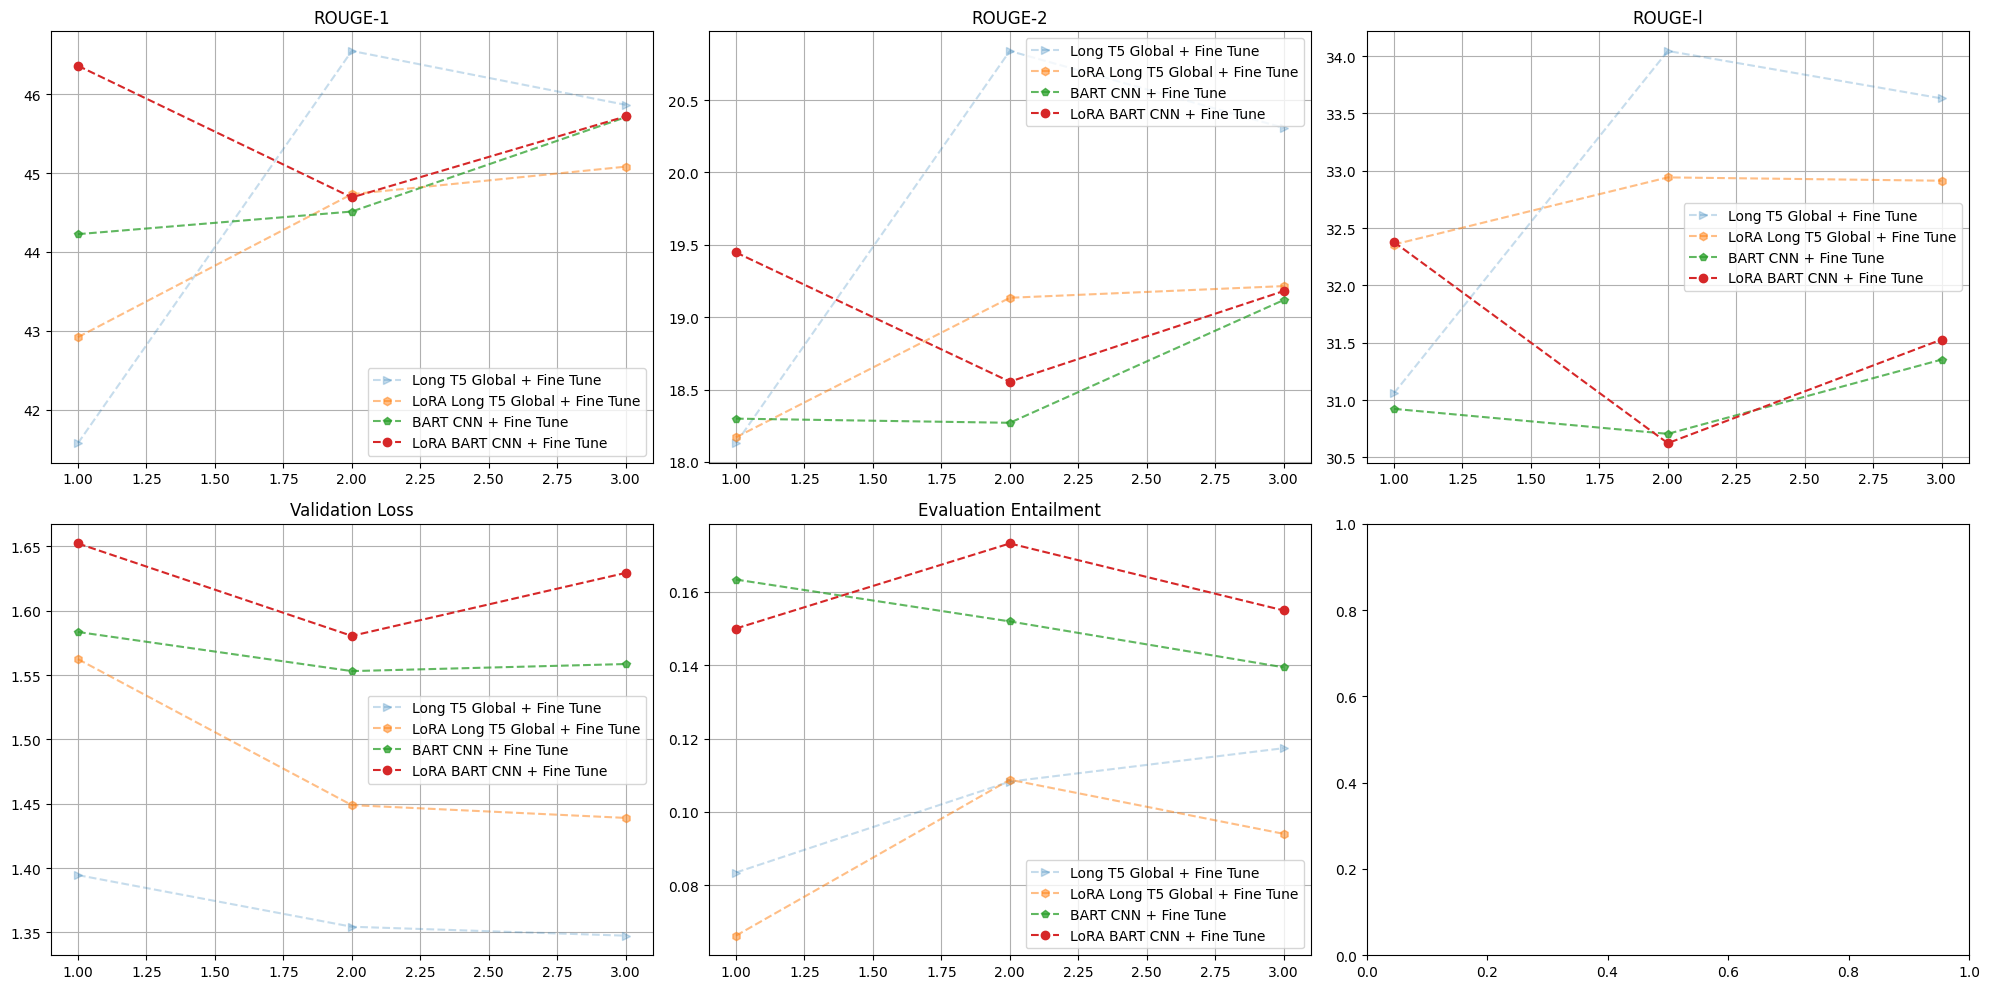

In [101]:
visualize_history_finetune(metric_for_visualization, 3)

/tmp/ipykernel_72672/4025058423.py:101: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


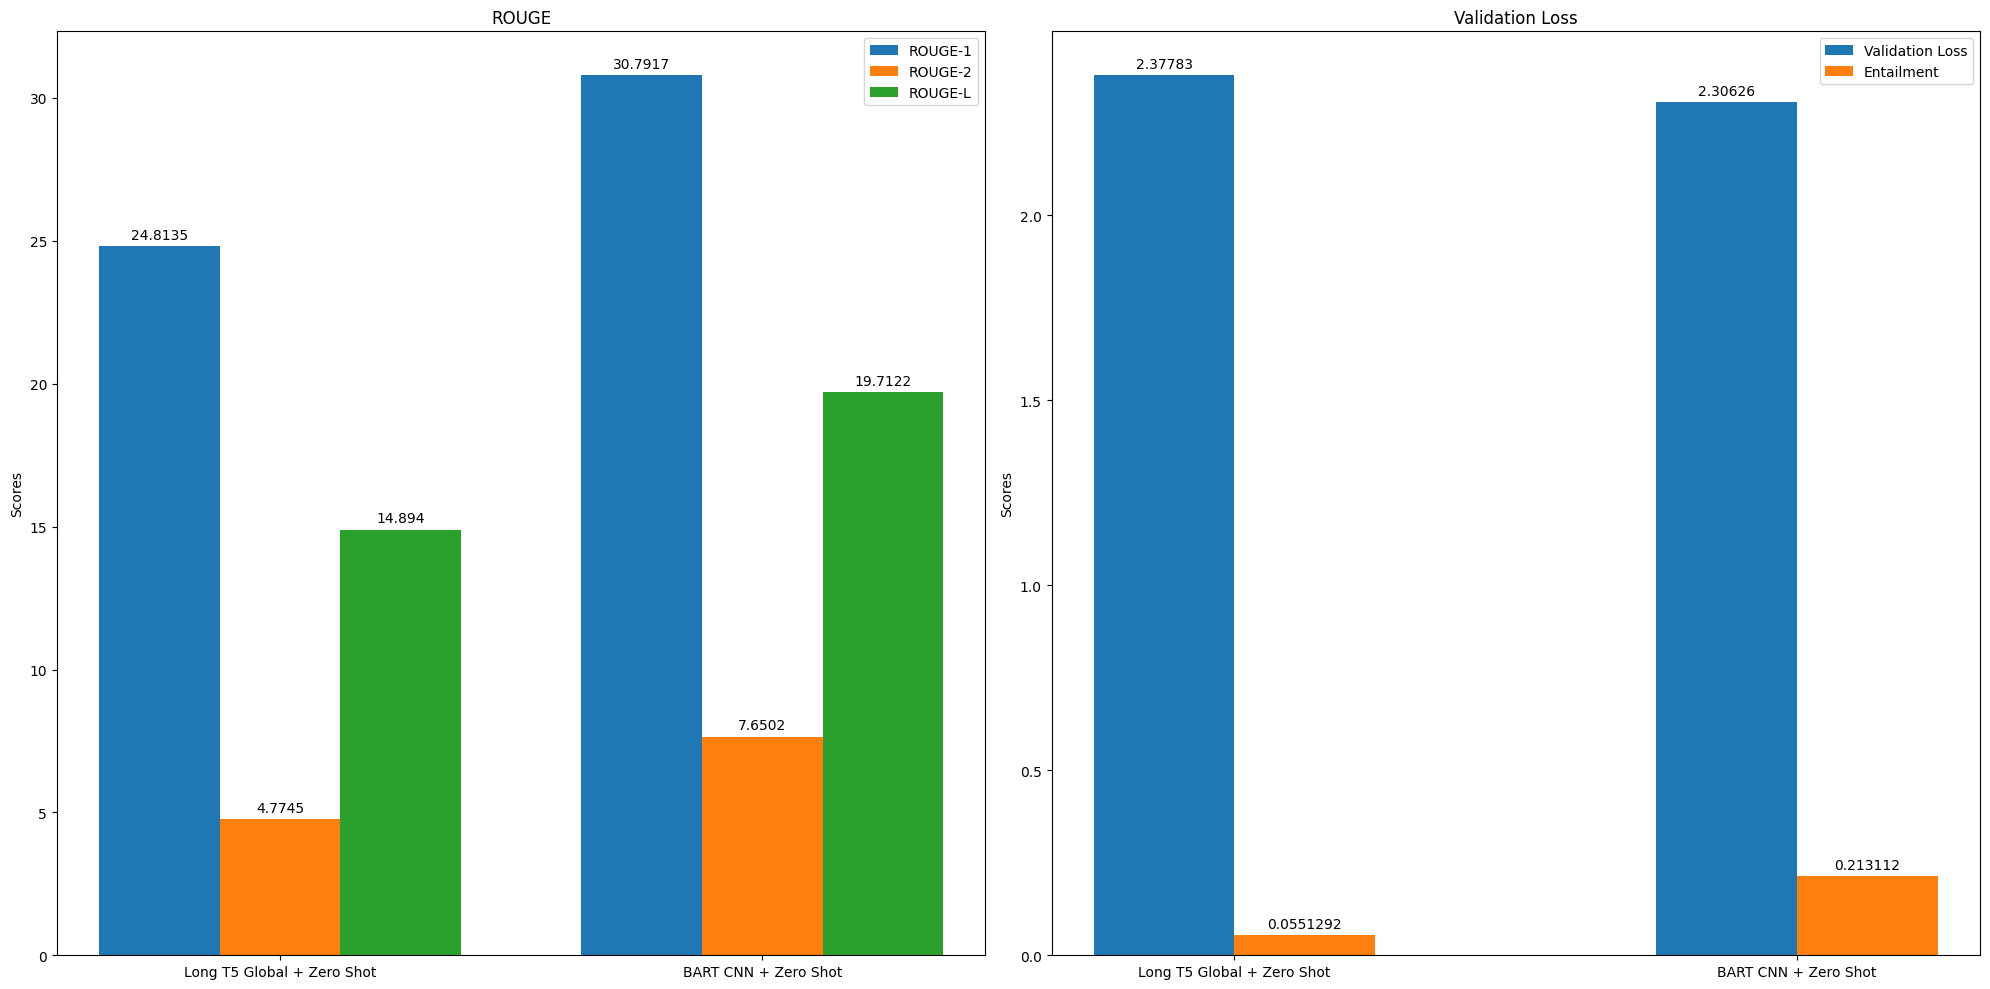

In [102]:
visualize_zeroshot(metric_for_visualization)

In [103]:
pd.DataFrame(metrics)

,Model,Method,GPU,Training Time,Rouge 1,Rouge 2,Rouge l,NLI Score
0,Long T5 Global,Zero Shot,3.729841,0.0000,24.8135,4.7745,14.8940,0.055129
1,Long T5 Global,Fine Tuning,3.811347,4726.3392,45.8648,20.3082,33.6309,0.117387
2,LoRA Long T5 Global,Fine Tuning,5.532691,7247.6890,44.7322,19.1340,32.9421,0.108786
3,BART CNN,Zero Shot,3.577353,0.0000,30.7917,7.6502,19.7122,0.213112
4,BART CNN,Fine Tuning,8.279986,1842.3234,44.2248,18.2992,30.9236,0.163378
5,LoRA BART CNN,Fine Tuning,12.268824,3001.8030,44.6905,18.5545,30.6245,0.173230


In [139]:
print(valid_ds['summary_instruction'][0])
print(f"target: {valid_ds['target'][0]}" )

Summarize Overcast - Walden and the Werewolf based on Reviews:
- I accidently ran around the game covered in oil after an oil wrestling match. I apologize for that being the reason all of your graphics are wet looking. That being said, I think the atmosphere is what makes this game freaky/scary. Alone in the dark, holding a one handed shotgun and all. The story is.....uh.....was that a story? My 3 year old niece tells me better stories than that.
- Despite the fact that the creators tried to make a good horror story (which I don't know if it's true or not), there's too many bad things in this game... Mediocre controls and a bad fighting mechanic (ever for the usual survival horror standards) accompanied by a terrible visibility (something that would only make sense if the lack of visibility was due to darkness or *spoiler alert* to the fact that the character was poisoned by the giant snake... not by a blurry camera almost constant in later stages) The story leaves something to be desi

In [132]:
FLAN_model = AutoModelForSeq2SeqLM.from_pretrained(FLAN_MODEL)
trainer_FLAN = Seq2SeqTrainer(
    FLAN_model,
    args=FLAN_training_args,
    train_dataset=tokenized_flan_dataset['train'],
    eval_dataset=tokenized_flan_dataset['valid'], 
    data_collator=data_collator_flan,
    compute_metrics=compute_metric_FLAN
)

output = trainer_FLAN.model.generate(**FLAN_tokenizer(valid_ds['summary_instruction'][0], return_tensors='pt', max_length=8192).to(device), max_new_tokens=150)


print(FLAN_tokenizer.decode(output[0], skip_special_tokens=True))
del FLAN_model, trainer_FLAN

Loading weights:   0%|          | 0/297 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


- Despite the fact that the creators tried to make a good horror story (which I don't know if it's true or not), there's too many bad things in this game... Mediocre controls and a bad fighting mechanic (ever for the usual survival horror standards) accompanied by a terrible visibility (something that would only make sense if the lack of visibility was due to darkness or *spoiler alert* to the fact that the character was poisoned by the giant snake... not by a blurry camera almost constant in later stages) The story leaves something to be desired and is a bit cliché with a terrible narration The soundtrack is good though - This game


In [133]:
FLAN_model = AutoModelForSeq2SeqLM.from_pretrained(f"{output_dir}/long-t5-global-finetune/checkpoint-378")
trainer_FLAN = Seq2SeqTrainer(
    FLAN_model,
    args=FLAN_training_args,
    train_dataset=tokenized_flan_dataset['train'],
    eval_dataset=tokenized_flan_dataset['valid'], 
    data_collator=data_collator_flan,
    compute_metrics=compute_metric_FLAN
)

output = trainer_FLAN.model.generate(**FLAN_tokenizer(valid_ds['summary_instruction'][0], return_tensors='pt', max_length=8192).to(device), max_new_tokens=150)

print(FLAN_tokenizer.decode(output[0], skip_special_tokens=True))
del FLAN_model, trainer_FLAN

Loading weights:   0%|          | 0/295 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Overcast - Walden and the Werewolf is a survival horror game with poor graphics, a poor story, and a poor soundtrack. The game has a good atmosphere and soundtrack, but the story is cliché and the controls are poor. The game is worth the price, but it is not worth the standard price.


In [134]:
FLAN_model = PeftModel.from_pretrained(AutoModelForSeq2SeqLM.from_pretrained(FLAN_MODEL) ,f"{output_dir}/LoRA-long-t5-global-finetune/checkpoint-252")
trainer_FLAN_LORA = Seq2SeqTrainer(
    FLAN_model,
    args=LoRA_FLAN_training_args,
    train_dataset=tokenized_flan_dataset['train'],
    eval_dataset=tokenized_flan_dataset['valid'], 
    data_collator=data_collator_flan,
    compute_metrics=compute_metric_FLAN
)

output = trainer_FLAN_LORA.model.generate(**FLAN_tokenizer(valid_ds['summary_instruction'][0], return_tensors='pt', max_length=8192).to(device), max_new_tokens=150)

print(FLAN_tokenizer.decode(output[0], skip_special_tokens=True))
del FLAN_model, trainer_FLAN_LORA

Loading weights:   0%|          | 0/297 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Walden and the Werewolf is a survival horror game with a dark atmosphere and a simple combat mechanic. The story is cliché and the soundtrack is good, but the graphics are poor and the controls are frustrating. The soundtrack is good, but the story is uninteresting and the narration is cliché. The game has a nice atmosphere, but it lacks substance.


In [ ]:
BART_CNN_model = AutoModelForSeq2SeqLM.from_pretrained(BART_CNN_MODEL)
trainer_BART_CNN = Seq2SeqTrainer(
    BART_CNN_model,
    args=BART_CNN_training_args,
    train_dataset=tokenized_bart_dataset['train'],
    eval_dataset=tokenized_bart_dataset['valid'], 
    data_collator=data_collator_bart,
    compute_metrics=compute_metric_BART
)

output = trainer_BART_CNN.model.generate(**BART_tokenizer(valid_ds['summary_instruction'][0], return_tensors='pt', max_length=4068).to(device), max_new_tokens=150)

print(BART_tokenizer.decode(output[0], skip_special_tokens=True))
del BART_CNN_model, trainer_BART_CNN

Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=150) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


This game is like watching a B movie. You know the movie isn't that great, but you enjoy yourself nonetheless. For the same price as a few gumballs at Cici's Pizza, it's not half bad. It's the kind of mindless horror game that I use to enjoy playing back in 2010 or '09.


In [52]:
output = trainer_BART_CNN.model.generate(**BART_tokenizer(valid_ds['summary_instruction'][0], return_tensors='pt', max_length=4068).to(device), max_new_tokens=150)

print(BART_tokenizer.decode(output[0], skip_special_tokens=True))

[transformers] Both `max_new_tokens` (=150) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Overcast - Walden and the Werewolf is a horror game with a negative atmosphere, negative graphics, negative story, and negative gameplay. The game has mediocre controls, a bad fighting mechanic, and a poor visibility. The story is uninteresting and the narration is cliché. The soundtrack is good, but the game has a lot of flaws and is not worth the standard price.


In [104]:
output = trainer_BART_LORA.model.generate(**BART_tokenizer(valid_ds['summary_instruction'][0], return_tensors='pt', max_length=4068).to(device), max_new_tokens=150)

print(BART_tokenizer.decode(output[0], skip_special_tokens=True))

[transformers] Both `max_new_tokens` (=150) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Walden and the Werewolf is a horror game with mediocre controls, a bad fighting mechanic, and poor visibility. The story leaves something to be desired and is a bit cliché with a terrible narration. The soundtrack is good, but the graphics are not that great and special effects strain the eyes. The game has value, but it is not worth the standard price.


### Select Best Model

Pilih model terbaik berdasarkan halusinasi terendah

In [114]:
import regex as re

premises = list(valid_ds["ground"])
def entailment_evaluation(trainer, eval_dataset, tokenizer, premises):
    preds = trainer.predict(eval_dataset).predictions

    preds = np.where(preds != -100, preds, tokenizer.pad_token_id)
    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)

    all_pairs, example_sent_ranges = [], []
    for premise, pred in zip(premises, decoded_preds):
        sents = [s.strip() for s in re.split(r"(?<=[.!?])\s+", pred.strip()) if s.strip()] # Strip kalimat prediksi berdasarkan tanda baca (.,!,?)
        if not sents:
            example_sent_ranges.append([])
            continue
        words = str(premise).split() # Split premise untuk mendapatkan panjang total premise
        chunks = [" ".join(words[i:i + 250]) for i in range(0, len(words), 250)] # Buat chunk dengan panjang 250
        sent_ranges = []
        for sent in sents:
            start = len(all_pairs) # Start awal untuk premise ke-i untuk prediksi
            all_pairs.extend((c, sent) for c in chunks) # Buat seluruh pair kemungkinan chunk dengan prediksi
            sent_ranges.append((start, len(all_pairs))) # Akhir dari premise ke-i untuk prediksi
        example_sent_ranges.append(sent_ranges)

    scores = NLI_model.predict(
        all_pairs, apply_softmax=True, batch_size=32, show_progress_bar=True
    )[:, 1]

    return float(np.mean([
        np.mean([scores[s:e].max() for s, e in sr]) if sr else 0.0
        for sr in example_sent_ranges
    ]))


In [124]:
def score_entailment_texts(premises, summaries):
    all_pairs, example_sent_ranges = [], []
    for premise, summary in zip(premises, summaries):
        sents = [s.strip() for s in re.split(r"(?<=[.!?])\s+", str(summary).strip()) if s.strip()]
        if not sents:
            example_sent_ranges.append([])
            continue
        words = str(premise).split()
        chunks = [" ".join(words[i:i + 250]) for i in range(0, len(words), 250)]
        sent_ranges = []
        for sent in sents:
            start = len(all_pairs)
            all_pairs.extend((c, sent) for c in chunks)
            sent_ranges.append((start, len(all_pairs)))
        example_sent_ranges.append(sent_ranges)

    scores = NLI_model.predict(
        all_pairs, apply_softmax=True, batch_size=32, show_progress_bar=True
    )[:, 1]

    return float(np.mean([
        np.mean([scores[s:e].max() for s, e in sr]) if sr else 0.0
        for sr in example_sent_ranges
    ]))

ceiling = score_entailment_texts(list(valid_ds["ground"]), list(valid_ds["target"]))
print("Dataset NLI ceiling (gold target):", ceiling)

Batches:   0%|          | 0/93 [00:00<?, ?it/s]

Dataset NLI ceiling (gold target): 0.2487076073884964


In [127]:
gc.collect()
torch.cuda.empty_cache()

BART_CNN_model = AutoModelForSeq2SeqLM.from_pretrained(BART_CNN_MODEL)
trainer_BART_CNN = Seq2SeqTrainer(
    BART_CNN_model,
    args=BART_CNN_training_args,
    train_dataset=tokenized_bart_dataset['train'],
    eval_dataset=tokenized_bart_dataset['valid'], 
    data_collator=data_collator_bart,
    compute_metrics=compute_metric_BART
)

print(entailment_evaluation(trainer_BART_CNN, tokenized_bart_dataset["valid"], BART_tokenizer, premises))
del BART_CNN_model

Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

Batches:   0%|          | 0/93 [00:00<?, ?it/s]

0.18067581951618195


In [115]:
gc.collect()
torch.cuda.empty_cache()

BART_CNN_model = AutoModelForSeq2SeqLM.from_pretrained(f"{output_dir}/BART-CNN-finetune/checkpoint-126")
trainer_BART_CNN = Seq2SeqTrainer(
    BART_CNN_model,
    args=BART_CNN_training_args,
    train_dataset=tokenized_bart_dataset['train'],
    eval_dataset=tokenized_bart_dataset['valid'], 
    data_collator=data_collator_bart,
    compute_metrics=compute_metric_BART
)

print(entailment_evaluation(trainer_BART_CNN, tokenized_bart_dataset["valid"], BART_tokenizer, premises))
del BART_CNN_model

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Batches:   0%|          | 0/95 [00:00<?, ?it/s]

0.25914785265922546


In [126]:
gc.collect()
torch.cuda.empty_cache()

print(entailment_evaluation(trainer_BART_LORA, tokenized_bart_dataset["valid"], BART_tokenizer, premises))

Batches:   0%|          | 0/108 [00:00<?, ?it/s]

0.25475040078163147


In [119]:
gc.collect()
torch.cuda.empty_cache()

FLAN_model = AutoModelForSeq2SeqLM.from_pretrained(f"{output_dir}/long-t5-global-finetune/checkpoint-378")
trainer_FLAN = Seq2SeqTrainer(
    FLAN_model,
    args=FLAN_training_args,
    train_dataset=tokenized_flan_dataset['train'],
    eval_dataset=tokenized_flan_dataset['valid'], 
    data_collator=data_collator_flan,
    compute_metrics=compute_metric_FLAN
)
print(entailment_evaluation(trainer_FLAN, tokenized_flan_dataset["valid"], FLAN_tokenizer, premises))
del FLAN_model

Loading weights:   0%|          | 0/295 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Batches:   0%|          | 0/94 [00:00<?, ?it/s]

0.23698671162128448


In [123]:
gc.collect()
torch.cuda.empty_cache()
FLAN_model = PeftModel.from_pretrained(AutoModelForSeq2SeqLM.from_pretrained(FLAN_MODEL) ,f"{output_dir}/LoRA-long-t5-global-finetune/checkpoint-252")
trainer_FLAN_LORA = Seq2SeqTrainer(
    FLAN_model,
    args=LoRA_FLAN_training_args,
    train_dataset=tokenized_flan_dataset['train'],
    eval_dataset=tokenized_flan_dataset['valid'], 
    data_collator=data_collator_flan,
    compute_metrics=compute_metric_FLAN
)

print(entailment_evaluation(trainer_FLAN_LORA, tokenized_flan_dataset["valid"], FLAN_tokenizer, premises))
del FLAN_model

Loading weights:   0%|          | 0/297 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Batches:   0%|          | 0/103 [00:00<?, ?it/s]

0.24591995775699615


In [125]:
gc.collect()
torch.cuda.empty_cache()

FLAN_model = AutoModelForSeq2SeqLM.from_pretrained(FLAN_MODEL)
trainer_FLAN = Seq2SeqTrainer(
    FLAN_model,
    args=FLAN_training_args,
    train_dataset=tokenized_flan_dataset['train'],
    eval_dataset=tokenized_flan_dataset['valid'], 
    data_collator=data_collator_flan,
    compute_metrics=compute_metric_FLAN
)
print(entailment_evaluation(trainer_FLAN, tokenized_flan_dataset["valid"], FLAN_tokenizer, premises))
del FLAN_model

Loading weights:   0%|          | 0/297 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Batches:   0%|          | 0/60 [00:00<?, ?it/s]

0.16029652953147888


### Model Deployment

In [141]:
!pip -q install pyngrok
!pip -q install python-dotenv
from pyngrok import ngrok
from dotenv import load_dotenv

load_dotenv()
api_key = os.getenv("NGROK_PHASE_3_TOKEN")
ngrok.set_auth_token(api_key)

In [156]:
deployed_model = AutoModelForSeq2SeqLM.from_pretrained(f"{output_dir}/BART-CNN-finetune/checkpoint-126").to(device)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

In [143]:
import threading
import time

from flask import Flask, jsonify, request
from werkzeug.serving import make_server


In [161]:
# Clear ngrok endpoint usage
ngrok.kill()

In [163]:
app = Flask(__name__)
port = 5000

public_url = ngrok.connect(port).public_url
app.config["BASE_URL"] = public_url

@app.route("/")
def index():
  return "Hello from Colab phase 3!"

@app.route("/inference", methods=["POST"])
def inference():
  if not request.is_json:
    return jsonify({"msg": "the POST method must be JSON with the body containing 'content'"})
  else:
    content = request.json["content"]
    output = deployed_model.generate(**BART_tokenizer(content, return_tensors='pt').to(device))
    return jsonify({"msg": BART_tokenizer.decode(output[0], skip_special_tokens=True)})

@app.route("/entailment_score", methods=["POST"])
def entailment_score():
  premise = request.json["premises"]
  hypothesis = request.json["hypothesis"]
  return jsonify({"score": score_entailment_texts(premise, hypothesis)})

class ThreadingServer(threading.Thread):
  def __init__(self, app, port):
    super().__init__()
    self.server = make_server("127.0.0.1", port, app)

  def run(self):
    print("Starting server")
    self.server.serve_forever()

  def shutdown(self):
    print("Shutting down server")
    self.server.shutdown()


In [164]:
print(f" * ngrok tunnel \"{public_url}\" -> \"http://127.0.0.1:{port}\"")

 * ngrok tunnel "https://ongoing-vacant-savor.ngrok-free.dev" -> "http://127.0.0.1:5000"


In [165]:
server_thread = ThreadingServer(app, 5000)
server_thread.start() # Create new process in OS level so no blocking

Starting server


In [160]:
# Scram button for shutting down the server
server_thread.shutdown()
server_thread.join()

Shutting down server
